# ARV blue: IDL column-offset correction

Replicate `fix_ARV_4278` from `fix_ZOR_4278_2026.pro` on an unrotated ARV 4278 Å TIFF frame. This is an additive DN correction, not masking or interpolation. The notebook leaves the TIFF and production calibration pipeline unchanged.

IDL `[column, row]` indexing becomes NumPy `[row, column]`. Start rows are inclusive; slices extend through the last row. Float arithmetic avoids unsigned-integer wraparound and preserves negative results.

| Column (zero-based) | First corrected row | Offset subtracted (DN) |
|---|---|---|
|281|153|77|
|282|153|47|
|342|146|47|
|343|146|429|
|344|146|10|


In [1]:
from pathlib import Path
import sys
import datetime as dt
import numpy as np
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "core/tiff_utils.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from core.tiff_utils import get_site_tiff_candidates, load_best_frame_from_tiffs

DATE = "20260210"
UTC = "102400"  # Change and rerun all cells to inspect another frame.
TARGET = dt.datetime.strptime(DATE + UTC, "%Y%m%d%H%M%S")


In [2]:
# Literal translation of the five IDL assignments; no transpose or rotation.
CORRECTIONS = ((281, 153, 77), (282, 153, 47), (342, 146, 47),
               (343, 146, 429), (344, 146, 10))

def fix_arv_4278(image):
    original = np.asarray(image)
    if original.ndim != 2 or original.shape[0] <= 153 or original.shape[1] <= 344:
        raise ValueError("Expected a 2-D image covering rows 0–153 and columns 0–344")
    corrected = original.astype(np.float64, copy=True)
    corrected[153:, 281] -= 77
    corrected[153:, 282] -= 47
    corrected[146:, 342] -= 47
    corrected[146:, 343] -= 429
    corrected[146:, 344] -= 10
    return corrected


In [3]:
candidates = get_site_tiff_candidates("ARV", DATE, "blue", mission="GNEISS")
if not candidates:
    raise FileNotFoundError(f"No ARV blue TIFFs for {DATE}")
# Prints TIFF, frame number, timing offset, and sidecar provenance.
raw, _ = load_best_frame_from_tiffs("ARV", candidates, TARGET, 0.90178, color="blue", correct_detector=False)
raw_saved = raw.copy()
corrected = fix_arv_4278(raw)
removed = raw.astype(float) - corrected
expected = np.zeros(raw.shape)
for column, start_row, offset in CORRECTIONS:
    expected[start_row:, column] = offset
np.testing.assert_array_equal(removed, expected)
np.testing.assert_array_equal(raw, raw_saved)
# Verify integer input does not wrap when subtracting from zero.
assert fix_arv_4278(np.zeros((512, 512), dtype=np.uint16))[146, 343] == -429
print(f"Shape: {raw.shape}; raw range: {raw.min():g}–{raw.max():g} DN")
print(f"Changed pixels: {np.count_nonzero(removed):,}; negative pixels after correction: {np.sum(corrected < 0):,}")
print("Verified exact offsets, inclusive start rows, unchanged other pixels, and unchanged input.")


ARV: THA260210_09595921_16bit.tif frame 1598/3991 (delta 0.15s, metadata /Users/anniepflaum/lab317/data/raw/asi/images/blue/ARV/THA260210_09595921_16bit.log)


Shape: (512, 512); raw range: 11–1083 DN
Changed pixels: 1,816; negative pixels after correction: 0
Verified exact offsets, inclusive start rows, unchanged other pixels, and unchanged input.


## Full frame before / after
Both images use the same raw-frame 1st–99.7th percentile display limits. These limits affect display only. The third panel shows exactly how much was subtracted.

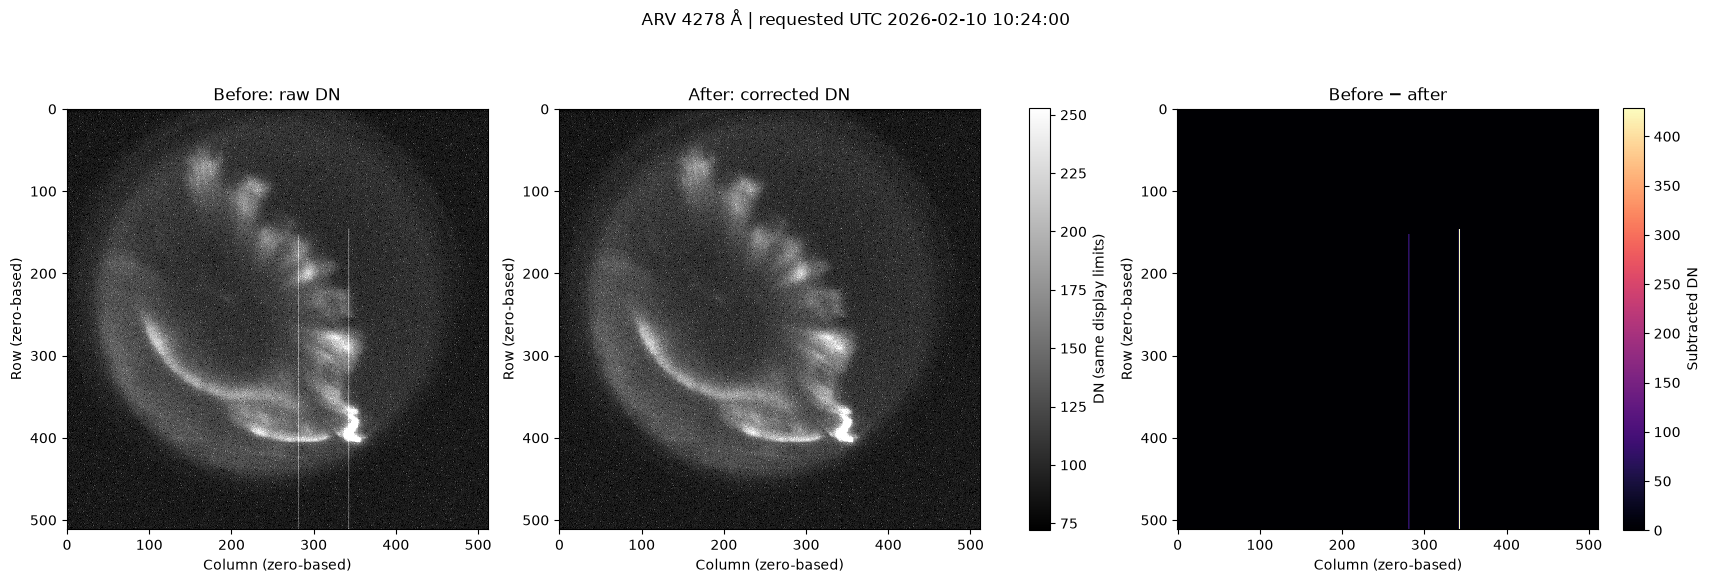

In [4]:
low, high = np.percentile(raw[np.isfinite(raw)], [1, 99.7])
fig, axes = plt.subplots(1, 3, figsize=(17, 6), layout="constrained")
for ax, image, title in zip(axes[:2], (raw, corrected), ("Before: raw DN", "After: corrected DN")):
    im = ax.imshow(image, origin="upper", cmap="gray", vmin=low, vmax=high, interpolation="nearest")
    ax.set_title(title)
fig.colorbar(im, ax=list(axes[:2]), label="DN (same display limits)", shrink=.75)
im = axes[2].imshow(removed, origin="upper", cmap="magma", vmin=0, vmax=429, interpolation="nearest")
axes[2].set_title("Before − after")
fig.colorbar(im, ax=axes[2], label="Subtracted DN", shrink=.75)
for ax in axes:
    ax.set_xlabel("Column (zero-based)")
    ax.set_ylabel("Row (zero-based)")
fig.suptitle(f"ARV 4278 Å | requested UTC {TARGET}")
plt.show()


## Inspect the streaks closely
The crops preserve detector pixel coordinates. Compare affected columns with their neighbors. Fixed offsets can overcorrect if the artifact changes with time; the correction does not estimate the offset from this frame.

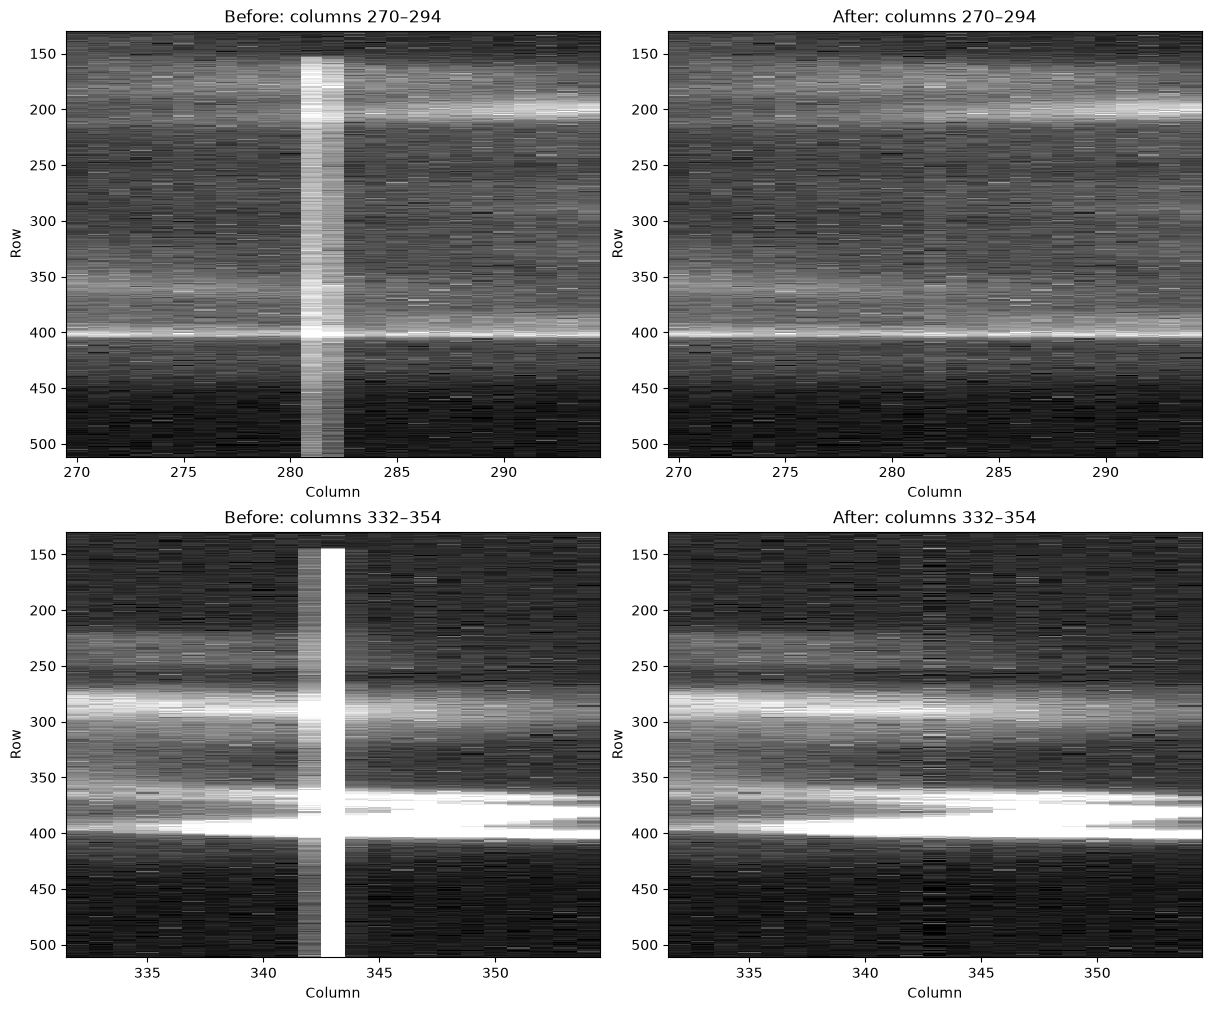

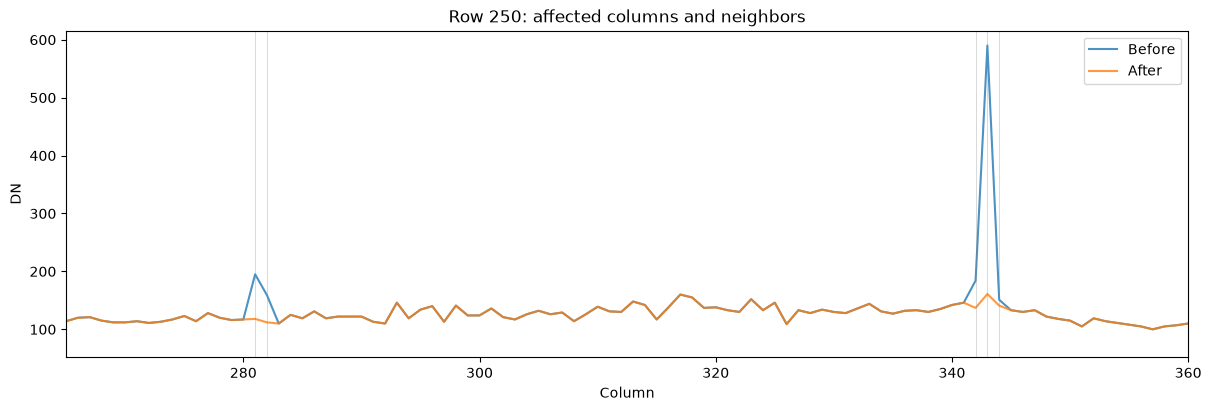

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10), layout="constrained")
for row, (left, right) in enumerate(((270, 294), (332, 354))):
    for col, (image, label) in enumerate(((raw, "Before"), (corrected, "After"))):
        ax = axes[row, col]
        ax.imshow(image, origin="upper", cmap="gray", vmin=low, vmax=high, interpolation="nearest")
        ax.set_xlim(left-.5, right+.5)
        ax.set_ylim(raw.shape[0]-.5, 130-.5)
        ax.set_aspect("auto")
        ax.set_title(f"{label}: columns {left}–{right}")
        ax.set_xlabel("Column")
        ax.set_ylabel("Row")
plt.show()

profile_row = min(250, raw.shape[0]-1)
fig, ax = plt.subplots(figsize=(12, 4), layout="constrained")
ax.plot(raw[profile_row], label="Before", alpha=.8)
ax.plot(corrected[profile_row], label="After", alpha=.8)
for column, _, _ in CORRECTIONS:
    ax.axvline(column, color="gray", alpha=.3, linewidth=.7)
ax.set(xlim=(265, 360), xlabel="Column", ylabel="DN", title=f"Row {profile_row}: affected columns and neighbors")
ax.legend()
plt.show()
